In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

candidates = [Path('i.csv'), Path('../recovered/i.csv'), Path('recovered/i.csv'), Path('data/i.csv'), Path('upload/i.csv'), Path('../upload/i.csv')]
DATA_PATH = next((p for p in candidates if p.is_file()), None)
if DATA_PATH is None:
    raise FileNotFoundError('i.csv를 노트북과 같은 폴더 또는 data 폴더에 놓아 주세요.')

df = pd.read_csv(DATA_PATH, encoding='euc-kr')
inbound = df.loc[df['입출'].astype(str).str.strip().eq('입항')].copy()
for col in ['입항일시', '출항일시']:
    inbound[col] = pd.to_datetime(inbound[col], errors='coerce')
inbound['승객'] = pd.to_numeric(inbound['승객'], errors='coerce')
inbound['날짜'] = inbound['입항일시'].dt.normalize()
inbound['연도'] = inbound['입항일시'].dt.year
inbound['월'] = inbound['입항일시'].dt.month
inbound['시각'] = inbound['입항일시'].dt.hour
inbound['요일'] = inbound['입항일시'].dt.dayofweek.map(dict(enumerate(['월','화','수','목','금','토','일'])))
inbound['입출항경과_시간'] = (inbound['출항일시'] - inbound['입항일시']).dt.total_seconds()/3600

# 실행 환경에 설치된 한글 글꼴을 우선 사용합니다.
from matplotlib import font_manager
font_names={f.name for f in font_manager.fontManager.ttflist}
for font in ['NanumGothic','Malgun Gothic','AppleGothic','Noto Sans CJK KR']:
    if font in font_names:
        plt.rcParams['font.family']=font
        break
plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.unicode_minus': False})
pd.set_option('display.max_columns', 30)
pd.set_option('display.max_rows', 30)
def bars(series, title, xlabel, ylabel, color='#286789'):
    ax = series.plot.bar(figsize=(10, 3.8), color=color, rot=0)
    ax.set(title=title, xlabel=xlabel, ylabel=ylabel)
    ax.grid(axis='y', alpha=.18)
    ax.set_axisbelow(True)
    plt.tight_layout()
    plt.show()

print('원본 데이터:', df.shape, ' / 입항 기록:', len(inbound))
print('입항일시 범위:', inbound['입항일시'].min(), '~', inbound['입항일시'].max())


원본 데이터: (3037, 32)  / 입항 기록: 1518
입항일시 범위: 2013-01-01 08:00:00 ~ 2026-10-16 10:00:00


,입항기록건수,자료구분
연도,,
2013,106,확보된 기록 합계
2014,104,확보된 기록 합계
2015,64,확보된 기록 합계
2016,205,확보된 기록 합계
2017,89,확보된 기록 합계
2018,80,확보된 기록 합계
2019,107,확보된 기록 합계
2020,0,입항 제한에 따른 0건: 사용자 설명
2021,0,입항 제한에 따른 0건: 사용자 설명


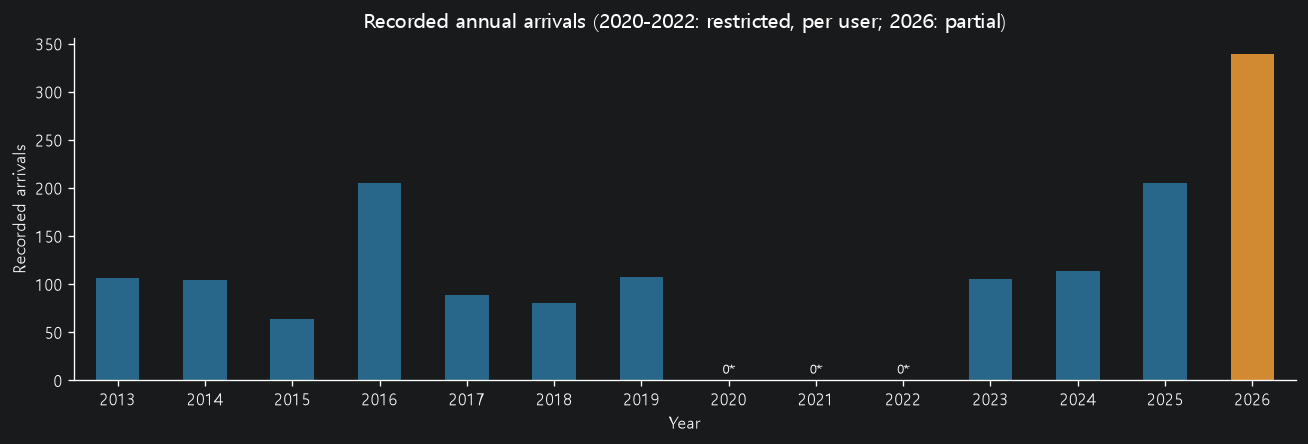

,확보된입항기록건수,확보된 기록 내 비중(%),기록존재연도수,집계연도수
월,,,,
1,56,3.69,7,11
2,51,3.36,9,11
3,135,8.89,11,11
4,219,14.43,11,11
5,207,13.64,11,11
6,158,10.41,11,11
7,125,8.23,11,11
8,143,9.42,11,11
9,160,10.54,11,11


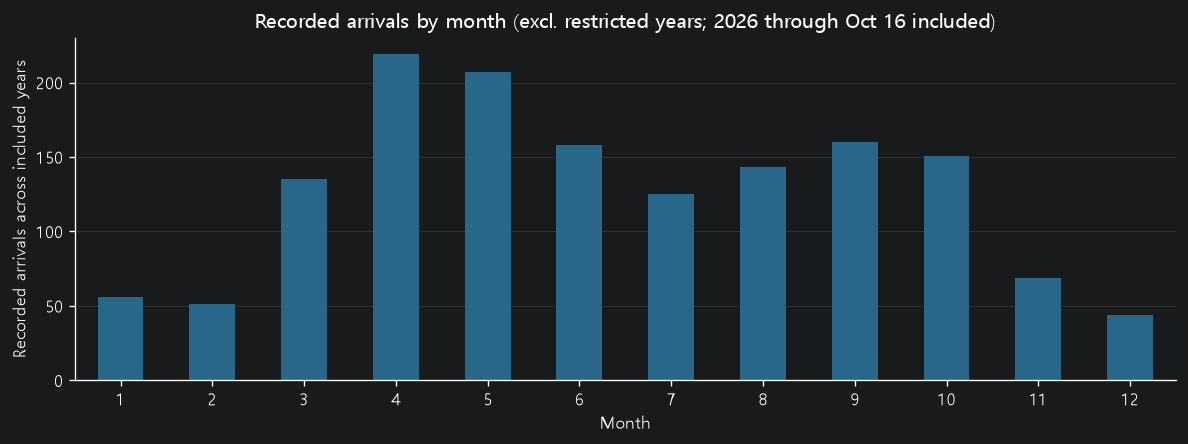

,연도,월,입항건수,처리근거
0,2013,2,0,팀의 입항 스케줄 부재 확인에 따라 0건 간주
1,2013,12,0,팀의 입항 스케줄 부재 확인에 따라 0건 간주
2,2015,1,0,팀의 입항 스케줄 부재 확인에 따라 0건 간주
3,2017,11,0,팀의 입항 스케줄 부재 확인에 따라 0건 간주
4,2017,12,0,팀의 입항 스케줄 부재 확인에 따라 0건 간주
5,2018,1,0,팀의 입항 스케줄 부재 확인에 따라 0건 간주
6,2018,12,0,팀의 입항 스케줄 부재 확인에 따라 0건 간주
7,2023,1,0,팀의 입항 스케줄 부재 확인에 따라 0건 간주
8,2023,2,0,팀의 입항 스케줄 부재 확인에 따라 0건 간주
9,2023,12,0,팀의 입항 스케줄 부재 확인에 따라 0건 간주


월별 평균 대상 연도: [np.int32(2013), np.int32(2014), np.int32(2015), np.int32(2016), np.int32(2017), np.int32(2018), np.int32(2019), np.int32(2023), np.int32(2024), np.int32(2025), np.int32(2026)]
무기록 월 0건 처리: 11 개; 승객 결측은 유지


In [6]:
restricted_years = [2020, 2021, 2022]  # 사용자 설명에 따른 실제 무입항 기간
annual_observed = inbound.groupby('연도').size().rename('입항기록건수')
annual = annual_observed.reindex(range(int(inbound['연도'].min()), int(inbound['연도'].max())+1)).to_frame()
annual['자료구분'] = '확보된 기록 합계'
annual.loc[restricted_years, '입항기록건수'] = 0
annual.loc[restricted_years, '자료구분'] = '입항 제한에 따른 0건: 사용자 설명'
annual.loc[2026, '자료구분'] = '10월 16일까지의 부분 자료'
annual['입항기록건수'] = annual['입항기록건수'].astype('Int64')
display(annual)
ax = annual['입항기록건수'].astype(float).plot.bar(figsize=(11,3.8), rot=0,
    color=['#d18a32' if y == 2026 else '#286789' for y in annual.index])
for year in restricted_years:
    ax.annotate('0*', (annual.index.get_loc(year), 0), xytext=(0,4),
                textcoords='offset points', ha='center', fontsize=8)
ax.set(title='Recorded annual arrivals (2020-2022: restricted, per user; 2026: partial)',
       xlabel='Year', ylabel='Recorded arrivals')
plt.tight_layout(); plt.show()

comparison = inbound.loc[~inbound['연도'].isin(restricted_years)].copy()
comparison_years = sorted(comparison['연도'].unique())
data_cutoff = inbound['입항일시'].max()
year_month_index = pd.MultiIndex.from_tuples([(year,month) for year in comparison_years for month in range(1,13) if year<data_cutoff.year or month<=data_cutoff.month],names=['연도','월'])
# 팀의 입항 스케줄 부재 확인을 반영하여 비교 기간 내 무기록 월은 0건 처리합니다.
year_month_raw = comparison.groupby(['연도','월']).size().reindex(year_month_index).astype('Int64')
zero_filled_months = year_month_raw[year_month_raw.isna()].rename('입항건수').reset_index()
zero_filled_months['입항건수'] = 0
zero_filled_months['처리근거'] = '팀의 입항 스케줄 부재 확인에 따라 0건 간주'
year_month = year_month_raw.fillna(0)
monthly = comparison.groupby('월').size().reindex(range(1,13)).rename('확보된입항기록건수').to_frame()
monthly['확보된 기록 내 비중(%)'] = monthly['확보된입항기록건수']/len(comparison)*100
monthly['기록존재연도수'] = year_month_raw.groupby('월').count()
monthly['집계연도수'] = year_month.groupby('월').count()
display(monthly.round(2))
bars(monthly['확보된입항기록건수'], 'Recorded arrivals by month (excl. restricted years; 2026 through Oct 16 included)',
     'Month', 'Recorded arrivals across included years')

display(zero_filled_months)
print('월별 평균 대상 연도:',comparison_years)
print('무기록 월 0건 처리:',len(zero_filled_months),'개; 승객 결측은 유지')


,입항건수,승객유효건수,확인승객합계,기록존재월수,승객결측건수,승객완전합계,전년대비입항증감률(%),자료구분
연도,,,,,,,,
2013,106.0,106.0,199170.0,10.0,0.0,199170.0,NaN,확보된 기록 합계
2014,104.0,104.0,240251.0,12.0,0.0,240251.0,-1.89,확보된 기록 합계
2015,64.0,64.0,161654.0,11.0,0.0,161654.0,-38.46,확보된 기록 합계
2016,205.0,205.0,560887.0,12.0,0.0,560887.0,220.31,확보된 기록 합계
2017,89.0,89.0,158128.0,10.0,0.0,158128.0,-56.59,확보된 기록 합계
2018,80.0,80.0,128795.0,10.0,0.0,128795.0,-10.11,확보된 기록 합계
2019,107.0,107.0,189053.0,12.0,0.0,189053.0,33.75,확보된 기록 합계
2020,0.0,0.0,0.0,0.0,0.0,0.0,-100.00,입항 제한에 따른 0건: 사용자 설명
2021,0.0,0.0,0.0,0.0,0.0,0.0,NaN,입항 제한에 따른 0건: 사용자 설명


,확보된입항기록건수,기록존재연도수,집계연도수,월별평균입항건수,확인승객합계,승객결측건수,승객완전합계
월,,,,,,,
1,56,7,11,5.09,94713.0,0,94713.0
2,51,9,11,4.64,113904.0,0,113904.0
3,135,11,11,12.27,190692.0,1,NaN
4,219,11,11,19.91,285971.0,0,285971.0
5,207,11,11,18.82,349666.0,0,349666.0
6,158,11,11,14.36,324960.0,0,324960.0
7,125,11,11,11.36,293863.0,0,293863.0
8,143,11,11,13.0,324633.0,0,324633.0
9,160,11,11,14.55,324031.0,0,324031.0


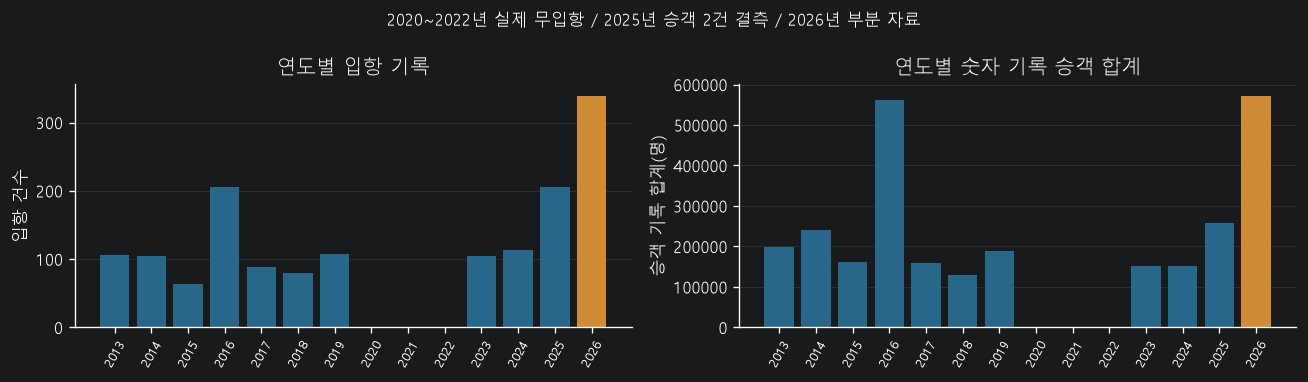

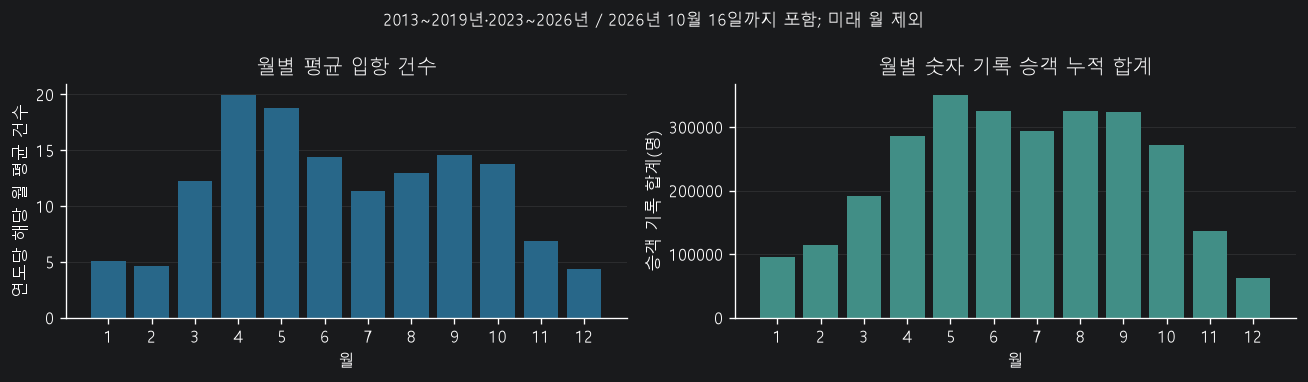

,항목,확인 내용
0,원자료 국적 열,없음
1,국적별 입항 건수 및 비율,미산출: 항차 시점의 선박 등록국 자료 필요
2,비율 정의,국적별 입항 건수 / 전체 입항 건수 × 100; 국적 미상도 별도 표시
3,해석 범위,선박 등록국이며 선사 소재국·승객 국적·사용 언어와 구분


In [7]:
# 연도별 승객은 입항 행의 기록값 합계입니다. 고유 여행객이나 실제 하선 인원이 아닙니다.
annual_details = inbound.groupby('연도').agg(
    입항건수=('승객','size'),승객유효건수=('승객','count'),
    확인승객합계=('승객',lambda s:s.sum(min_count=1)),기록존재월수=('월','nunique'))
annual_details = annual_details.reindex(annual.index)
annual_details['승객결측건수'] = annual_details['입항건수']-annual_details['승객유효건수']
annual_details['승객완전합계'] = annual_details['확인승객합계'].where(annual_details['승객결측건수'].eq(0))
annual_details.loc[restricted_years,['입항건수','승객유효건수','확인승객합계','승객결측건수','승객완전합계','기록존재월수']] = 0
annual_details['전년대비입항증감률(%)'] = (annual_details['입항건수']/annual_details['입항건수'].shift(1)-1)*100
annual_details.loc[annual_details['입항건수'].shift(1).le(0)|annual_details.index.to_series().eq(2026),'전년대비입항증감률(%)'] = np.nan
annual_details['자료구분'] = annual['자료구분']
annual_details.loc[2025,'자료구분'] = '확보된 기록 합계; 승객 2건 결측'
display(annual_details.round(2))

# 월별 평균은 실제 관측 범위에 해당하는 연월만 분모에 포함합니다.
monthly_details = monthly[['확보된입항기록건수','기록존재연도수','집계연도수']].copy()
monthly_details['월별평균입항건수'] = year_month.groupby('월').mean()
monthly_details['확인승객합계'] = comparison.groupby('월')['승객'].sum(min_count=1).reindex(range(1,13))
monthly_details['승객결측건수'] = comparison.groupby('월')['승객'].apply(lambda s:s.isna().sum()).reindex(range(1,13))
monthly_details['승객완전합계'] = monthly_details['확인승객합계'].where(monthly_details['승객결측건수'].eq(0))
display(monthly_details.round(2))

fig,axes=plt.subplots(1,2,figsize=(11,3.2))
colors=['#cf8b35' if y==2026 else '#286789' for y in annual_details.index]
axes[0].bar(annual_details.index.astype(str),annual_details['입항건수'],color=colors)
axes[1].bar(annual_details.index.astype(str),annual_details['확인승객합계'],color=colors)
axes[0].set(title='연도별 입항 기록',ylabel='입항 건수')
axes[1].set(title='연도별 숫자 기록 승객 합계',ylabel='승객 기록 합계(명)')
for ax in axes:ax.tick_params(axis='x',rotation=60,labelsize=8);ax.grid(axis='y',alpha=.15);ax.set_axisbelow(True)
axes[1].ticklabel_format(style='plain',axis='y')
fig.suptitle('2020~2022년 실제 무입항 / 2025년 승객 2건 결측 / 2026년 부분 자료',fontsize=10)
plt.tight_layout();plt.show()

fig,axes=plt.subplots(1,2,figsize=(11,3.2))
axes[0].bar(monthly_details.index,monthly_details['월별평균입항건수'],color='#286789')
axes[1].bar(monthly_details.index,monthly_details['확인승객합계'],color='#418e86')
axes[0].set(title='월별 평균 입항 건수',ylabel='연도당 해당 월 평균 건수')
axes[1].set(title='월별 숫자 기록 승객 누적 합계',ylabel='승객 기록 합계(명)')
for ax in axes:ax.set_xticks(range(1,13));ax.set_xlabel('월');ax.grid(axis='y',alpha=.15);ax.set_axisbelow(True)
axes[1].ticklabel_format(style='plain',axis='y')
fig.suptitle('2013~2019년·2023~2026년 / 2026년 10월 16일까지 포함; 미래 월 제외',fontsize=10)
plt.tight_layout();plt.show()

# 원자료에 국적 열이 없어 외내 구분이나 선명으로 선박 국적을 임의 추정하지 않습니다.
nationality_available = '선박국적' in df.columns
nationality_status = pd.DataFrame([
    ('원자료 국적 열','있음' if nationality_available else '없음'),
    ('국적별 입항 건수 및 비율','미산출: 항차 시점의 선박 등록국 자료 필요'),
    ('비율 정의','국적별 입항 건수 / 전체 입항 건수 × 100; 국적 미상도 별도 표시'),
    ('해석 범위','선박 등록국이며 선사 소재국·승객 국적·사용 언어와 구분')
],columns=['항목','확인 내용'])
display(nationality_status)
